lấy file từ drive

**Cài package ở chế độ editable**
```python
%cd /content/drive/MyDrive/your_pj
!pip install -e .
```
Sau đó, ở bất kỳ notebook nào trong Colab, bạn đều có thể import:
```python
from miniai.training import fit
```
**Khi bạn sửa notebook và export lại**
```python
import nbdev
nbdev.nbdev_export()
```
Bạn chỉ cần import lại module trong Colab để sử dụng phiên bản mới. Nếu module đã được import trước đó, Python có thể vẫn giữ phiên bản cũ trong bộ nhớ. Khi đó, sử dụng:
```python
import importlib
import miniai.training

importlib.reload(miniai.training)

from miniai.training import fit
```



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
#%cd /content/drive/MyDrive/your_pj

In [ ]:
#!pip install -e .

Obtaining file:///content/drive/MyDrive/miniai_pj
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for miniai_pj (pyproject.toml) ... done
  Created wheel for miniai_pj: filename=miniai_pj-0.0.1-0.editable-py3-none-any.whl size=3140 sha256=ae3b6af62a53c8d951ac588ac32830c41f3e416fc24b1f8d021394f5e452aa88
  Stored in directory: /tmp/pip-ephem-wheel-cache-x877vltz/wheels/50/7f/17/29fdce142dfaa0c21c055b958ebb6f882371bed67242fb4d3b
Successfully built miniai_pj


# default_exp

In [ ]:
#| default_exp datasets

In [ ]:
#|export
from __future__ import annotations
import math, numpy as np, matplotlib.pyplot as plt
from operator import itemgetter
from itertools import zip_longest
import fastcore.all as fc

from torch.utils.data import default_collate

from miniai.training import *

In [ ]:
import logging, pickle,gzip, os, time, shutil, torch, matplotlib as mpl
from pathlib import Path

from torch import tensor, nn, optim
from torch.utils.data import DataLoader
import torch.nn.functional as F
from datasets import load_dataset, load_dataset_builder

import torchvision.transforms.functional as TF
from fastcore.test import test_close

In [ ]:
torch.set_printoptions(precision=2, linewidth=140, sci_mode=False)
torch.manual_seed(1)
mpl.rcParams['image.cmap'] = 'gray'

In [ ]:
logging.disable(logging.WARNING)

# hugging face datasets

In [ ]:
name = "zalando-datasets/fashion_mnist"
ds_builder = load_dataset_builder(name)
print(ds_builder.info.description)

README.md:   0%|          | 0.00/9.02k [00:00<?, ?B/s]

In [ ]:
ds_builder.info.features

{'image': Image(mode=None, decode=True),
 'label': ClassLabel(names=['T - shirt / top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'])}

In [ ]:
ds_builder.info.splits

{'train': SplitInfo(name='train', num_bytes=31049107.0, num_examples=60000),
 'test': SplitInfo(name='test', num_bytes=5192560.0, num_examples=10000)}

In [ ]:
dsd = load_dataset(name)
dsd

fashion_mnist/train-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 30.9MB            

fashion_mnist/train-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

fashion_mnist/test-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B / 5.18MB            

fashion_mnist/test-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/60000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})

In [ ]:
train, test = dsd['train'], dsd['test']
train[0]

{'image': <PIL.PngImagePlugin.PngImageFile image mode=L size=28x28>,
 'label': 9}

In [ ]:
x,y = ds_builder.info.features

In [ ]:
x,y

('image', 'label')

In [ ]:
x,y = 'image', 'label'
img = train[0][x]
img

In [ ]:
xb = train[:5][x]
yb = train[:5][y]
yb

[9, 0, 0, 3, 0]

In [ ]:
featy = train.features[y]
featy

ClassLabel(names=['T - shirt / top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'])

In [ ]:
featy.int2str(yb)

['Ankle boot',
 'T - shirt / top',
 'T - shirt / top',
 'Dress',
 'T - shirt / top']

In [ ]:
train['label'][:5]

[9, 0, 0, 3, 0]

Giả sử Dataset trả về mỗi sample có dạng:
```python
{
    'image': image,
    'label': 2
}
```
Khi DataLoader lấy 3 samples, b sẽ có dạng:
```python
b = [
    {'image': image1, 'label': 2},
    {'image': image2, 'label': 0},
    {'image': image3, 'label': 1}
]
```
`[o[x] for o in b]`

Với x = 'image', nó tương đương:
```python
[
    b[0]['image'],
    b[1]['image'],
    b[2]['image']
]
```
Kết quả là một list chứa 3 ảnh.

`TF.to_tensor()`: chuyển từng ảnh thành Tensor, shape lúc này là (1,28,28)

`torch.stack([...])`: ghép các Tensor thành một Tensor mới theo một chiều mới.

VD:
```python
img1.shape = (1, 28, 28)
img2.shape = (1, 28, 28)
img3.shape = (1, 28, 28)
```
Sau khi stack:
```python
#(3, 1, 28, 28)
torch.stack([img1, img2, img3]).shape

```

In [ ]:
def collate_fn(b):
  return {x:torch.stack([TF.to_tensor(o[x]) for o in b]),
          y:tensor([o[y] for o in b])}

In [ ]:
dl = DataLoader(train, collate_fn=collate_fn, batch_size=16)
b = next(iter(dl))
b[x].shape, b[y]

(torch.Size([16, 1, 28, 28]),
 tensor([9, 0, 0, 3, 0, 2, 7, 2, 5, 5, 0, 9, 5, 5, 7, 9]))

In [ ]:
def transforms(b):
  b[x] = [TF.to_tensor(o) for o in b[x]]
  return b

In [ ]:
tds = train.with_transform(transforms)
dl = DataLoader(tds, batch_size=16)
b = next(iter(dl))
b[x].shape, b[y]

(torch.Size([16, 1, 28, 28]),
 tensor([9, 0, 0, 3, 0, 2, 7, 2, 5, 5, 0, 9, 5, 5, 7, 9]))

sử dụng **higher-order function (hàm bậc cao)** và **in-place modification (thay đổi trực tiếp dữ liệu)** để tạo ra một hàm transformi có nhiệm vụ biến đổi dữ liệu trong batch.

**1. Hàm _transformi(b)**

Giả sử b là batch có dạng:
```python
b = {
    'image': [img1, img2, img3],
    'label': tensor([2, 0, 1])
}
```
`x='image'`

chuyển ảnh từ PIL thành Tensor sau đó làm phẳng Tensor thành Tensor 1 chiều

```python
img.shape
# (1, 28, 28)

torch.flatten(img).shape
# (784,)
```

`b[x] = [...]`: Gán list các ảnh đã được flatten trở lại vào dictionary b.

```python
b = {
    'image': [
        tensor(...),  # Shape (784,)
        tensor(...),  # Shape (784,)
        tensor(...)   # Shape (784,)
    ],
    'label': tensor([2, 0, 1])
}
```
trả về None

**2. Hàm inplace(f)**

hàm nhận một hàm khác làm đầu vào

Cụ thể:
- inplace(f) nhận một function f.
- Bên trong nó định nghĩa function _f(b).
- _f(b) gọi f(b) để thực hiện biến đổi dữ liệu.
- Sau đó return b để trả về batch đã được biến đổi.

trả về b vì `_transformi(b)` chỉ thay đổi trực tiếp dict b chứ không trả về b

nhưng khi sử dụng `inplace()` thì tạo ra một function mới có thể vừa thực hiện biến đổi vừa trả về batch




In [ ]:
# biến đổi dữ liệu ảnh trong batch thành các vector 1 chiều
def _transformi(b):
  b[x] = [torch.flatten(TF.to_tensor(o)) for o in b[x]]

In [ ]:
#|export
def inplace(f):
  def _f(b):
    f(b)
    return b
  return _f

- Truyền function _transformi vào inplace.

- inplace tạo function _f.

- Trả về function _f.

- Gán function _f cho biến transformi.

Vì vậy, về bản chất: `transformi = _f`

Khi gọi: `result = transformi(b)`

nó tương đương với:

```python
def _f(b):
    _transformi(b)
    return b
```
Kết quả là result chứa batch đã được biến đổi.

có thể gộp lại từ đầu nhưng việc tách ra giúp tách biệt 2 việc:

- _transformi: Chỉ chịu trách nhiệm biến đổi dữ liệu.

- inplace: Chịu trách nhiệm bọc hàm để trả về dữ liệu sau khi biến đổi.

Nhờ đó, có thể tái sử dụng `inplace()` cho nhiều hàm biến đổi khác nhau mà không cần viết lại `return b`.

In [ ]:
transformi = inplace(_transformi)

In [ ]:
r = train.with_transform(transformi)[0]
r[x].shape, r[y]

(torch.Size([784]), 9)

Dấu @ ở đầu một function là cú pháp Decorator trong Python.

Nó cho phép áp dụng một hàm khác lên function đang được định nghĩa.

tương tự như cách viết ở trên

In [ ]:
@inplace
def transformi(b):
  b[x] = [torch.flatten(TF.to_tensor(o)) for o in b[x]]

In [ ]:
tdsf = train.with_transform(transformi)
r = tdsf[0]
r[x].shape, r[y]

(torch.Size([784]), 9)

In [ ]:
d = dict(a=1,b=2,c=3)
ig = itemgetter('a', 'c')
ig(d)

(1, 3)

In [ ]:
class D:
  def __getitem__(self,k):
    return 1 if k=='a' else 2 if k=='b' else 3

In [ ]:
d = D()
ig(d)

(1, 3)

In [ ]:
list(tdsf.features)

['image', 'label']

In [ ]:
batch = dict(a=[1], b=[2]), dict(a=[3], b=[4])
default_collate(batch)

{'a': [tensor([1, 3])], 'b': [tensor([2, 4])]}

In [ ]:
#|export
def collate_dict(ds):
  get = itemgetter(*ds.features)
  def _f(b): return get(default_collate(b))
  return _f

In [ ]:
dlf = DataLoader(tdsf, batch_size=4, collate_fn=collate_dict(tdsf))
xb,yb = next(iter(dlf))
xb.shape, yb

(torch.Size([4, 784]), tensor([9, 0, 0, 3]))

# ploting images

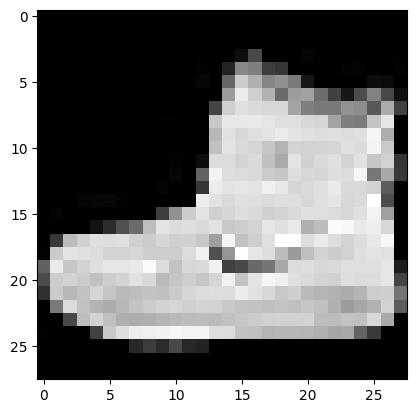

In [ ]:
b = next(iter(dl))
xb = b['image']
img = xb[0]
plt.imshow(img[0])

Decorator `@fc.delegates(plt.Axes.imshow)`. Đây là decorator delegates của thư viện fastcore.

`imshow()` là phương thức của Matplotlib dùng để hiển thị ảnh trên một Axes.

```python
fig, ax = plt.subplots()
ax.imshow(img, cmap='gray', interpolation='nearest')
```
Ở đây:
- cmap='gray': Hiển thị ảnh với thang màu xám.
- interpolation='nearest': Phương pháp nội suy khi hiển thị ảnh.

Vấn đề là `show_image() `cũng muốn hỗ trợ những tham số như cmap, interpolation, alpha, vmin, vmax... của `imshow()`. Nhưng nếu khai báo thủ công tất cả tham số này thì code sẽ rất dài. Nên sử dụng decorator

Decorator này giúp **đưa các tham số ** của `plt.Axes.imshow()` **vào phần signature (chữ ký hàm)** của `show_image()`, thông qua **kwargs.

Lưu ý: delegates không tự động thực hiện việc hiển thị ảnh hay truyền tham số. Việc truyền tham số thực sự được thực hiện bởi `ax.imshow(im, **kwargs)` ở bên dưới.

`if fc.hasattrs(im, ('cpu', 'permute', 'detach')):` kiểm tra kiểu dữ liệu của ảnh, iểm tra xem object im có đầy đủ các attributes được chỉ định hay không.

Ở đây kiểm tra 3 attributes:
- cpu: Chuyển Tensor về CPU.
- permute: Thay đổi thứ tự các chiều.
- detach: Tách Tensor khỏi computational graph.

Nếu có đủ 3 attributes thì code xem im là một PyTorch Tensor hoặc object có giao diện tương tự Tensor.

`im.detach().cpu()`:

- detach(): Tách Tensor khỏi computational graph, không còn theo dõi gradient.

- cpu(): Chuyển Tensor về CPU nếu nó đang nằm trên GPU.

`if len(im.shape)==3 and im.shape[0]<5`: kiểm tra ảnh có 3 chiều hay không và chiều đầu tiên có kích thước nhỏ hơn 5 hay không

`elif not isinstance(im, np.array): im= np.array(im)`: nếu ảnh không phải tensor và không phải numpy array thì chuyển thành numpy array

```python
# ví dụ
im = PIL.Image.open('image.png')
im = np.array(im)
```

`if im.shape[-1]==1`: xử lý ảnh grayscale

im.shape[-1] lấy kích thước của chiều cuối cùng. Nếu bằng 1, nghĩa là ảnh có một channel ở chiều cuối (VD: (28,28,1)) kết quả sau đó sẽ là (28,28).

Vì Matplotlib có thể hiển thị ảnh grayscale dưới dạng ma trận 2 chiều (H, W). Do đó không cần giữ chiều channel có kích thước 1.

Lưu ý: ... là dấu đại diện cho tất cả các chiều trước chiều cuối. Vì vậy im[..., 0] tương đương im[:, :, 0] trong trường hợp ảnh 3 chiều.


- set_title(title): Đặt tiêu đề cho ảnh.

- set_xticks([]): Ẩn các tick trên trục X.

- set_yticks([]): Ẩn các tick trên trục Y.

- axis('off'): Ẩn toàn bộ trục, bao gồm cả khung hiển thị.

trả về ax để có thể tiếp tục dùng ax sau khi gọi hàm

```python
# ví dụ
ax = show_image(img)
ax.set_title('My Image')
```

In [ ]:
#|export
@fc.delegates(plt.Axes.imshow)
def show_image(im, ax=None, figsize=None, title=None, noframe=True, **kwargs):
  "Show a PIL or Pytorch image on `ax`"
  if fc.hasattrs(im, ('cpu', 'permute', 'detach')):
    im = im.detach().cpu()
    if len(im.shape)==3 and im.shape[0]<5: im = im.permute(1,2,0)
  elif not isinstance(im, np.ndarray): im= np.array(im)
  if im.shape[-1]==1: im=im[...,0]
  if ax is None: _,ax = plt.subplots(figsize=figsize)
  ax.imshow(im,**kwargs)
  if title is not None: ax.set_title(title)
  ax.set_xticks([])
  ax.set_yticks([])
  if noframe: ax.axis('off')
  return ax

In [ ]:
help(show_image)

Help on function show_image in module __main__:

show_image(
    im,
    ax=None,
    figsize=None,
    title=None,
    noframe=True,
    *,
    cmap=None,
    norm=None,
    aspect=None,
    interpolation=None,
    alpha=None,
    vmin=None,
    vmax=None,
    colorizer=None,
    origin=None,
    extent=None,
    interpolation_stage=None,
    filternorm=True,
    filterrad=4.0,
    resample=None,
    url=None,
    data=None
)
    Show a PIL or Pytorch image on `ax`



<Axes: >

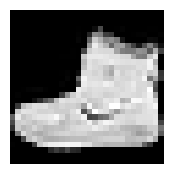

In [ ]:
show_image(img, figsize=(2,2))

<Axes: >

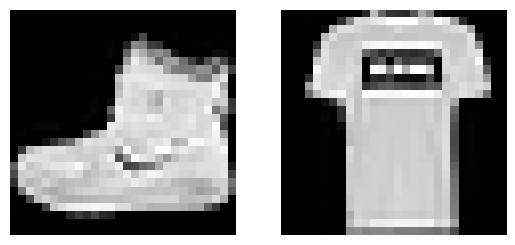

In [ ]:
fig, axs = plt.subplots(1,2)
show_image(img, axs[0])
show_image(xb[1], axs[1])

Lưu ý về `imsize`: Đây là kích thước được dùng để tính Figure, không phải thay đổi kích thước pixel gốc của ảnh.

```python
if nrows*ncols==1:
    ax=np.array([ax])
```
Khi tạo nhiều Axes `fig, ax = plt.subplots(2, 2)`, ax là một NumPy Array `ax.shape ->(2, 2)`. Nhưng khi chỉ tạo một Axes `fig, ax = plt.subplots(1, 1)`, ax không phải NumPy Array mà là một đối tượng Axes đơn lẻ vì vậy chuyển Axes đơn lẻ thành NumPy Array chứa một phần tử.

*Lưu ý: Code này chỉ xử lý trường hợp nrows * ncols == 1. Với nhiều Axes, nếu squeeze=True (mặc định của Matplotlib), ax có thể là mảng 1 chiều hoặc 2 chiều tùy số hàng và cột.*

Ví dụ sử dụng:
```python
fig, ax = subplots(2, 3, imsize=3)

for a in ax.flat:
    show_image(img, ax=a)

plt.show()
```
Ở đây ax.flat giúp duyệt qua tất cả Axes trong mảng, bất kể mảng có 1 hay 2 chiều.

In [ ]:
#|export
@fc.delegates(plt.subplots, keep=True)
def subplots(
    nrows:int=1, #Number of rows in returned axes grid
    ncols:int=1, #Number of columns in returned axes grid
    figsize:tuple=None, #Witdth, height in inches of the returned figure
    imsize:int=3, #size (in inches) of images that will be displayed in the returned figure
    suptitle:str=None, # title to be set to returned figure
    **kwargs
):
  "A figure and set of subplots to display images of `imsize` inches"
  if figsize is None: figsize=(ncols*imsize, nrows*imsize)
  fig,ax = plt.subplots(nrows, ncols, figsize=figsize, **kwargs)
  if suptitle is not None: fig.suptitle(suptitle)
  if nrows*ncols==1: ax=np.array([ax])
  return fig,ax

In [ ]:
!pip install nbdev

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 38.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [nbdev]


In [ ]:
from nbdev.showdoc import show_doc

In [ ]:
show_doc(subplots)

---

### subplots

```python
def subplots(
    nrows:int=1, # Number of rows in returned axes grid
    ncols:int=1, # Number of columns in returned axes grid
    figsize:tuple=None, # Witdth, height in inches of the returned figure
    imsize:int=3, # size (in inches) of images that will be displayed in the returned figure
    suptitle:str=None, # title to be set to returned figure
    *, sharex:"bool | Literal['none', 'all', 'row', 'col']"=False,
    sharey:"bool | Literal['none', 'all', 'row', 'col']"=False, squeeze:bool=True,
    width_ratios:Sequence[float] | None=None, height_ratios:Sequence[float] | None=None,
    subplot_kw:dict[str, Any] | None=None, gridspec_kw:dict[str, Any] | None=None, **kwargs
):
```

*A figure and set of subplots to display images of `imsize` inches*

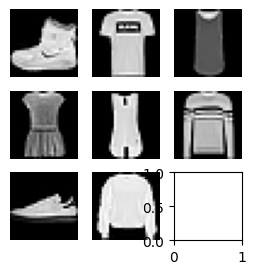

In [ ]:
fig,axs = subplots(3,3,imsize=1)
imgs = xb[:8]
for ax,img in zip(axs.flat, imgs): show_image(img,ax)

tạo một grid gồm n Axes để hiển thị n ảnh, tự động tính số hàng và số cột nếu người dùng không chỉ định.

Lưu ý: get_grid() có tham số title riêng, còn subplots() có suptitle. Hai tham số này có mục đích tương tự nhưng tên khác nhau.

muốn hiển thị 10 ảnh thì gọi `get_grid(10)` Hàm sẽ tự tính số hàng và số cột.

Toán tử or có nghĩa:
- Nếu ncols đã có giá trị khác 0 thì giữ nguyên.
- Nếu ncols là None hoặc 0 thì tính lại.

Tại sao sử dụng ceil() thay vì floor()? Vì cần đủ số Axes để chứa tất cả 10 ảnh.

ceil: 10 images / 3 cols = 4 rows (show 10 images)

floor: 10 images / 3 cols = 3 rows (show 9 images not 10)

In [ ]:
#|export
@fc.delegates(subplots)
def get_grid(
    n:int, #Number of axes
    nrows:int=None, #Number of rows, defaulting to `int(math.sqrt(n))`
    ncols:int=None, #Number of columns, defaulting to `ceil(n/rows)`
    title:str=None, # If passed, title set to the figure
    weight:str='bold', # title font weight
    size:int=14, #title font size
    **kwargs
):
  "return a grid of `n` axes, `rows` by `cols`"
  if nrows: ncols = ncols or int(np.ceil(n/nrows))
  elif ncols: nrows = nrows or int(np.ceil(n/ncols))
  else:
    nrows = int(math.sqrt(n))
    ncols = int(np.ceil(n/nrows))
  fig,axs = subplots(nrows, ncols, **kwargs)
  for i in range(n, nrows*ncols):
    axs.flat[i].set_axis_off() # ẩn các axes k sử dụng, flat: làm phẳng axes thành 1 iterator 1 chiều
  if title is not None:
    fig.suptitle(title, weight=weight, size=size)
  return fig,axs

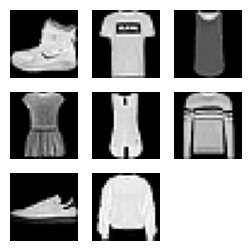

In [ ]:
fig, axs = get_grid(8, nrows=3, imsize=1)
for ax,img in zip(axs.flat, imgs):
  show_image(img, ax)

In [ ]:
#|export
@fc.delegates(subplots)
def show_images(
    ims:list, #images to show
    nrows:int|None=None, #Number of rows in grid
    ncols:int|None=None, #number of columns in grid(auto-caculated if None)
    titles:list|None=None, #optinal list of titles for each image
    **kwargs
):
  "show all images `ims` as subplots with `rows` using `titles`"
  axs = get_grid(len(ims), nrows, ncols, **kwargs)[1].flat
  for im,t,ax in zip_longest(ims, titles or [], axs):
    show_image(im,ax=ax,title=t)

In [ ]:
yb = b['label']
lbls = yb[:8]

In [ ]:
names = "top trouser Pullover Dess Coat Sandal Shirt Sneaker Bag Boot".split()
titles = itemgetter(*lbls)(names)
' '.join(titles)

'Boot top top Dess top Pullover Sneaker Pullover'

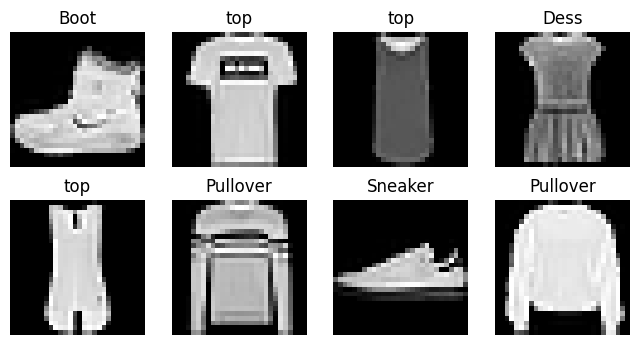

In [ ]:
show_images(imgs, imsize=2, titles=titles)

In [ ]:
#|export
class DataLoader:
  def __init__(self, *dls): self.train, self.valid = dls[:2]

  @classmethod
  def from_dd(cls, dd, batch_size, as_tupe=True, **kwargs):
    f = collate_dict(dd['train'])
    return cls(*get_dls(*dd.values(),bs=batch_size, collate_fn=f, **kwargs))

# export

In [ ]:
import nbdev; nbdev.nbdev_export()